In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("retail-orders-raw.csv")

print(df.head())
print(df.shape)
print(df.info())

  order_id  order_date customer_segment       city       category quantity  \
0  RT-1001  2026-01-03          Student    Chennai   Learning Kit        2   
1  RT-1002  03/01/2026          Fresher  Bengaluru  Course Access        1   
2  RT-1003  2026-01-05          student    Chennai  Course Access        1   
3  RT-1004  2026-01-07     Professional  Hyderabad   Learning Kit        3   
4  RT-1004  2026-01-07     Professional  Hyderabad   Learning Kit        3   

   unit_price  discount_pct payment_status  
0         799          10.0           Paid  
1        1499           0.0           paid  
2        1499           NaN        Pending  
3         799           5.0           Paid  
4         799           5.0           Paid  
(12, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          12 non-null     object 
 1   order

In [3]:
print(df.isnull().sum())

order_id            0
order_date          1
customer_segment    0
city                1
category            0
quantity            0
unit_price          0
discount_pct        1
payment_status      0
dtype: int64


In [4]:
df = df.drop_duplicates()

print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [11]:
df["order_date"] = pd.to_datetime(
    df["order_date"],
    errors="coerce",
    dayfirst=True
)

df["quantity"] = pd.to_numeric(
    df["quantity"],
    errors="coerce"
)

print("Data types after correction:")
print(df.dtypes)

display(df[["order_date", "quantity"]].head())

Data types after correction:
order_id                    object
order_date          datetime64[ns]
customer_segment            object
city                        object
category                    object
quantity                   float64
unit_price                   int64
discount_pct               float64
payment_status              object
order_year                 float64
order_month                float64
gross_sales                float64
net_sales                  float64
dtype: object


,order_date,quantity
0,2026-03-01,2.0
1,NaT,1.0
2,2026-05-01,1.0
3,2026-07-01,3.0
5,2026-09-01,1.0


In [12]:
df["city"] = df["city"].fillna("Unknown")

df["quantity"] = df["quantity"].fillna(
    df["quantity"].median()
)

print("Missing values after handling:")
print(df.isnull().sum())

display(df[["city", "quantity"]].head())

Missing values after handling:
order_id            0
order_date          5
customer_segment    0
city                0
category            0
quantity            0
unit_price          0
discount_pct        1
payment_status      0
order_year          5
order_month         5
gross_sales         0
net_sales           1
dtype: int64


,city,quantity
0,Chennai,2.0
1,Bengaluru,1.0
2,Chennai,1.0
3,Hyderabad,3.0
5,Unknown,1.0


In [13]:
df["gross_sales"] = (
    df["quantity"] * df["unit_price"]
)

df["net_sales"] = (
    df["gross_sales"] *
    (1 - df["discount_pct"] / 100)
)

print("Sales calculation:")
display(df[[
    "order_id",
    "quantity",
    "unit_price",
    "discount_pct",
    "gross_sales",
    "net_sales"
]])


Sales calculation:


,order_id,quantity,unit_price,discount_pct,gross_sales,net_sales
0,RT-1001,2.0,799,10.0,1598.0,1438.20
1,RT-1002,1.0,1499,0.0,1499.0,1499.00
2,RT-1003,1.0,1499,NaN,1499.0,NaN
3,RT-1004,3.0,799,5.0,2397.0,2277.15
5,RT-1005,1.0,999,0.0,999.0,999.00
6,RT-1006,-1.0,799,10.0,-799.0,-719.10
7,RT-1007,2.0,999,105.0,1998.0,-99.90
8,RT-1008,1.0,1499,0.0,1499.0,1499.00
9,RT-1009,1.0,799,0.0,799.0,799.00
10,RT-1010,2.0,1499,15.0,2998.0,2548.30


In [14]:
df.to_csv("clean_dataset.csv", index=False)

print("Clean dataset exported successfully!")

Clean dataset exported successfully!


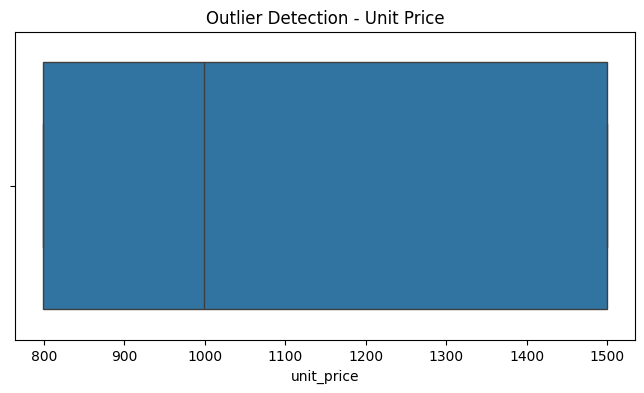

In [15]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["unit_price"])
plt.title("Outlier Detection - Unit Price")
plt.show()

In [16]:
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month

display(df.head())

,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,order_year,order_month,gross_sales,net_sales
0,RT-1001,2026-03-01,Student,Chennai,Learning Kit,2.0,799,10.0,Paid,2026.0,3.0,1598.0,1438.20
1,RT-1002,NaT,Fresher,Bengaluru,Course Access,1.0,1499,0.0,paid,NaN,NaN,1499.0,1499.00
2,RT-1003,2026-05-01,student,Chennai,Course Access,1.0,1499,NaN,Pending,2026.0,5.0,1499.0,NaN
3,RT-1004,2026-07-01,Professional,Hyderabad,Learning Kit,3.0,799,5.0,Paid,2026.0,7.0,2397.0,2277.15
5,RT-1005,2026-09-01,Fresher,Unknown,Mentor Session,1.0,999,0.0,Failed,2026.0,9.0,999.0,999.00


In [18]:
import pandas as pd

raw = pd.read_csv("retail-orders-raw.csv")

df = raw.copy()

print("Original dataset loaded successfully!")
print(raw.shape)

Original dataset loaded successfully!
(12, 9)


In [19]:
print("Original dataset:", raw.shape)
print("Cleaned dataset:", df.shape)

Original dataset: (12, 9)
Cleaned dataset: (12, 9)


In [20]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate records:")
print(df.duplicated().sum())

print("Final dataset information:")
df.info()

Missing values:
order_id            0
order_date          1
customer_segment    0
city                1
category            0
quantity            0
unit_price          0
discount_pct        1
payment_status      0
dtype: int64
Duplicate records:
1
Final dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          12 non-null     object 
 1   order_date        11 non-null     object 
 2   customer_segment  12 non-null     object 
 3   city              11 non-null     object 
 4   category          12 non-null     object 
 5   quantity          12 non-null     object 
 6   unit_price        12 non-null     int64  
 7   discount_pct      11 non-null     float64
 8   payment_status    12 non-null     object 
dtypes: float64(1), int64(1), object(7)
memory usage: 996.0+ bytes


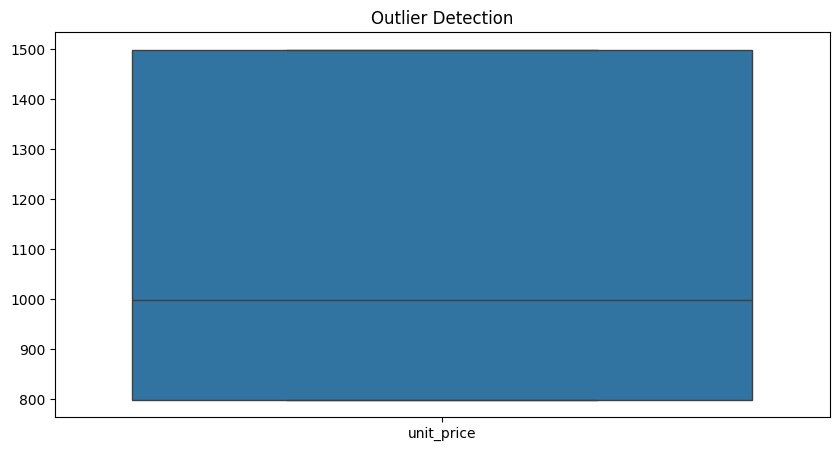

Outlier detection completed!


In [21]:
# OUTLIER DETECTION

plt.figure(figsize=(10, 5))

sns.boxplot(data=df[["unit_price", "quantity"]])

plt.title("Outlier Detection")
plt.show()

print("Outlier detection completed!")

In [24]:
# CONVERT DATA INTO NUMERIC FORMAT

df["unit_price"] = pd.to_numeric(
    df["unit_price"], errors="coerce"
)

df["quantity"] = pd.to_numeric(
    df["quantity"], errors="coerce"
)

print(df[["unit_price", "quantity"]].dtypes)

unit_price      int64
quantity      float64
dtype: object


In [25]:
df["unit_price"] = df["unit_price"].fillna(
    df["unit_price"].median()
)

df["quantity"] = df["quantity"].fillna(
    df["quantity"].median()
)

print("Missing numeric values handled!")

Missing numeric values handled!


In [26]:
# HANDLE OUTLIERS USING IQR

for col in ["unit_price", "quantity"]:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

    print(col, "Lower limit:", lower)
    print(col, "Upper limit:", upper)

print("Outliers handled successfully!")

display(df[["unit_price", "quantity"]])

unit_price Lower limit: -251.0
unit_price Upper limit: 2549.0
quantity Lower limit: -0.5
quantity Upper limit: 3.5
Outliers handled successfully!


,unit_price,quantity
0,799,2.0
1,1499,1.0
2,1499,1.0
3,799,3.0
4,799,3.0
5,999,1.0
6,799,-0.5
7,999,2.0
8,1499,1.0
9,799,1.0


In [27]:
# FEATURE ENGINEERING

df["order_date"] = pd.to_datetime(
    df["order_date"], errors="coerce", dayfirst=True
)

df["order_year"] = df["order_date"].dt.year

df["order_month"] = df["order_date"].dt.month

df["order_month_name"] = df["order_date"].dt.month_name()

print("Feature engineering completed!")

display(df[[
    "order_id",
    "order_date",
    "order_year",
    "order_month",
    "order_month_name"
]])

Feature engineering completed!


,order_id,order_date,order_year,order_month,order_month_name
0,RT-1001,2026-03-01,2026.0,3.0,March
1,RT-1002,NaT,NaN,NaN,NaN
2,RT-1003,2026-05-01,2026.0,5.0,May
3,RT-1004,2026-07-01,2026.0,7.0,July
4,RT-1004,2026-07-01,2026.0,7.0,July
5,RT-1005,2026-09-01,2026.0,9.0,September
6,RT-1006,2026-10-13,2026.0,10.0,October
7,RT-1007,2026-12-01,2026.0,12.0,December
8,RT-1008,NaT,NaN,NaN,NaN
9,RT-1009,NaT,NaN,NaN,NaN


In [28]:
# SALES CALCULATION

df["gross_sales"] = (
    df["quantity"] * df["unit_price"]
)

df["discount_amount"] = (
    df["gross_sales"] * df["discount_pct"] / 100
)

df["net_sales"] = (
    df["gross_sales"] - df["discount_amount"]
)

print("Sales calculation completed!")

display(df[[
    "order_id",
    "quantity",
    "unit_price",
    "discount_pct",
    "gross_sales",
    "discount_amount",
    "net_sales"
]])

Sales calculation completed!


,order_id,quantity,unit_price,discount_pct,gross_sales,discount_amount,net_sales
0,RT-1001,2.0,799,10.0,1598.0,159.80,1438.20
1,RT-1002,1.0,1499,0.0,1499.0,0.00,1499.00
2,RT-1003,1.0,1499,NaN,1499.0,NaN,NaN
3,RT-1004,3.0,799,5.0,2397.0,119.85,2277.15
4,RT-1004,3.0,799,5.0,2397.0,119.85,2277.15
5,RT-1005,1.0,999,0.0,999.0,0.00,999.00
6,RT-1006,-0.5,799,10.0,-399.5,-39.95,-359.55
7,RT-1007,2.0,999,105.0,1998.0,2097.90,-99.90
8,RT-1008,1.0,1499,0.0,1499.0,0.00,1499.00
9,RT-1009,1.0,799,0.0,799.0,0.00,799.00


In [29]:
# BEFORE AND AFTER COMPARISON

print("BEFORE CLEANING")
print("Rows:", raw.shape[0])
print("Columns:", raw.shape[1])

print("\nAFTER CLEANING")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

BEFORE CLEANING
Rows: 12
Columns: 9

AFTER CLEANING
Rows: 12
Columns: 15


In [30]:
# FINAL VALIDATION

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nFinal Cleaned Dataset:")
display(df.head(10))

Missing Values:
order_id            0
order_date          5
customer_segment    0
city                1
category            0
quantity            0
unit_price          0
discount_pct        1
payment_status      0
order_year          5
order_month         5
order_month_name    5
gross_sales         0
discount_amount     1
net_sales           1
dtype: int64

Duplicate Records:
1

Data Types:
order_id                    object
order_date          datetime64[ns]
customer_segment            object
city                        object
category                    object
quantity                   float64
unit_price                   int64
discount_pct               float64
payment_status              object
order_year                 float64
order_month                float64
order_month_name            object
gross_sales                float64
discount_amount            float64
net_sales                  float64
dtype: object

Final Cleaned Dataset:


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,order_year,order_month,order_month_name,gross_sales,discount_amount,net_sales
0,RT-1001,2026-03-01,Student,Chennai,Learning Kit,2.0,799,10.0,Paid,2026.0,3.0,March,1598.0,159.80,1438.20
1,RT-1002,NaT,Fresher,Bengaluru,Course Access,1.0,1499,0.0,paid,NaN,NaN,NaN,1499.0,0.00,1499.00
2,RT-1003,2026-05-01,student,Chennai,Course Access,1.0,1499,NaN,Pending,2026.0,5.0,May,1499.0,NaN,NaN
3,RT-1004,2026-07-01,Professional,Hyderabad,Learning Kit,3.0,799,5.0,Paid,2026.0,7.0,July,2397.0,119.85,2277.15
4,RT-1004,2026-07-01,Professional,Hyderabad,Learning Kit,3.0,799,5.0,Paid,2026.0,7.0,July,2397.0,119.85,2277.15
5,RT-1005,2026-09-01,Fresher,NaN,Mentor Session,1.0,999,0.0,Failed,2026.0,9.0,September,999.0,0.00,999.00
6,RT-1006,2026-10-13,Student,Pune,Learning Kit,-0.5,799,10.0,Paid,2026.0,10.0,October,-399.5,-39.95,-359.55
7,RT-1007,2026-12-01,Professional,Mumbai,Mentor Session,2.0,999,105.0,Paid,2026.0,12.0,December,1998.0,2097.90,-99.90
8,RT-1008,NaT,Fresher,Bengaluru,Course Access,1.0,1499,0.0,Pending,NaN,NaN,NaN,1499.0,0.00,1499.00
9,RT-1009,NaT,Student,Chennai,Learning Kit,1.0,799,0.0,Paid,NaN,NaN,NaN,799.0,0.00,799.00


In [31]:
# EXPORT CLEAN DATASET

df.to_csv("clean_dataset.csv", index=False)

print("Clean dataset exported successfully!")

Clean dataset exported successfully!


In [32]:
from google.colab import files

files.download("clean_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>